# 4.9 Time Series Forecasting

Forecasting means predicting the future values of a series from its past: atmospheric CO$_2$, river discharge, glacier flow, groundwater levels. This notebook is a shootout. The model families of this book are pointed at one real series, evaluated on the same temporal split with the same metrics, and a table built in code decides.

| Contestant | From |
|---|---|
| Naive persistence and seasonal naive | always first |
| SARIMA (`statsmodels`) | classical statistics |
| Gradient boosting on lag features (`lightgbm`) | Chapter 3 |
| A small LSTM and a small transformer encoder (`torch`) | notebook 4.4 |

**The series.** Mauna Loa monthly CO$_2$ (NOAA Global Monitoring Laboratory, 1958 to 2024): long, regular, strongly seasonal, with a smooth trend. Then three questions a single score hides: do the prediction intervals mean what they claim, where does skill run out with lead time, and are rare large events forecast at all (on a synthetic series where we know each event's size).

The notebook ends with the class leaderboard: a public CO$_2$ track (a diagnostic) and a hidden synthetic track (graded).

🖥️ [**Lecture slides — Session 26 (Wed Dec 2)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec26_forecasting.html)

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pooch
import torch
import torch.nn as nn

import mlgeo_synth

np.random.seed(0)
torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")
print("device:", device)

# One fixed color per model, reused in every figure (Okabe-Ito palette, colorblind-safe).
COLORS = {
    "observations":   "#000000",
    "naive":          "#999999",
    "seasonal naive": "#E69F00",
    "SARIMA":         "#0072B2",
    "ARIMA":          "#0072B2",
    "LightGBM":       "#009E73",
    "LSTM":           "#D55E00",
    "Transformer":    "#CC79A7",
}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

device: mps


## 1. Data

### 1.1 Mauna Loa monthly CO$_2$

The longest continuous direct measurement of atmospheric CO$_2$, started by Charles Keeling in 1958. NOAA GML distributes monthly means as a text file; `pooch` downloads it once and caches it.

In [2]:
co2_url = "https://raw.githubusercontent.com/UW-MLGEO/MLGeo-dataset/main/data/data_co2.csv"
co2_file = pooch.retrieve(co2_url, known_hash=None, fname="data_co2.csv")

co2 = pd.read_csv(co2_file, comment="#", sep=r"\s+", header=0)
co2.columns = ["year", "month", "decimal_date", "average",
               "deseasonalized", "ndays", "stdev", "unc"]
co2.index = pd.to_datetime(co2["year"].astype(str) + "-"
                           + co2["month"].astype(str).str.zfill(2))
y_full = co2["average"].astype("float64")
print(y_full.shape, "monthly values,", y_full.index[0].date(), "to", y_full.index[-1].date())

(798,) monthly values, 1958-03-01 to 2024-08-01


### 1.2 The leaderboard holdout: hands off the last 12 months

Before any modeling we remove the final 12 months, **2023-09 through 2024-08**: they are the leaderboard holdout (section 6), scored once. Nothing before section 6 touches them.

In [3]:
holdout_months = y_full.index[-12:]
y = y_full.iloc[:-12].copy()
del y_full  # the holdout values are gone from this notebook

print("holdout months:", holdout_months.strftime("%Y-%m").tolist())
print("working series:", y.index[0].date(), "to", y.index[-1].date(), f"({len(y)} months)")

holdout months: ['2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06', '2024-07', '2024-08']
working series: 1958-03-01 to 2023-08-01 (786 months)


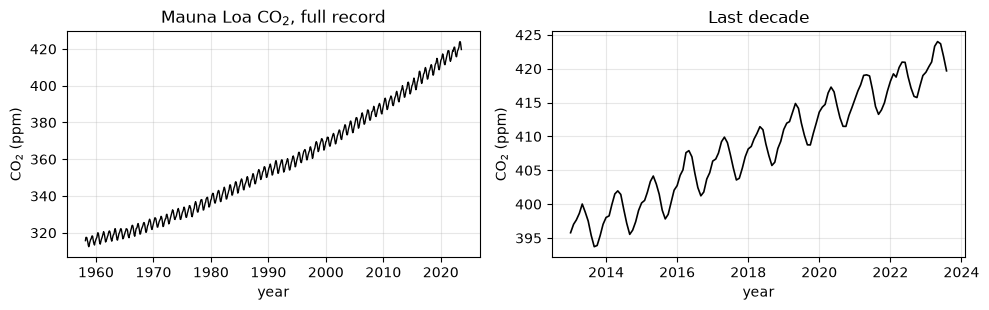

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(y.index, y.values, color=COLORS["observations"], lw=1)
axes[0].set_title("Mauna Loa CO$_2$, full record")
axes[1].plot(y.loc["2013":].index, y.loc["2013":].values,
             color=COLORS["observations"], lw=1.2)
axes[1].set_title("Last decade")
for ax in axes:
    ax.set_xlabel("year")
    ax.set_ylabel("CO$_2$ (ppm)")
fig.tight_layout()
plt.show()

A smooth, accelerating trend plus a sawtooth annual cycle: northern-hemisphere vegetation draws CO$_2$ down each summer. A model that cannot beat "repeat last year's shape" here has learned nothing.

## 2. Evaluation protocol

### 2.1 One temporal split for every model

A forecast is tested fairly only on data from **after** everything it was trained on. A random split lets the model interpolate between the neighbors of each test month, which inflates the score and predicts nothing. TEST is the final 48 months of the working series, **2019-09 through 2023-08**; TRAIN is everything before. Every model forecasts the whole 48-month window in one go, without seeing any test value.

In [5]:
H_CO2 = 48
train_co2, test_co2 = y.iloc[:-H_CO2], y.iloc[-H_CO2:]
print(f"train {train_co2.index[0].date()} .. {train_co2.index[-1].date()} ({len(train_co2)} months), "
      f"test {test_co2.index[0].date()} .. {test_co2.index[-1].date()} ({len(test_co2)} months)")

train 1958-03-01 .. 2019-08-01 (738 months), test 2019-09-01 .. 2023-08-01 (48 months)


### 2.2 Metrics

With forecast errors $e_t = y_t - \hat{y}_t$ over the $n$ test months:

| Metric | Formula | Read it as |
|---|---|---|
| MSE | $\frac{1}{n}\sum e_t^2$ | squared units, dominated by large errors |
| RMSE | $\sqrt{\mathrm{MSE}}$ | data units, still dominated by large errors |
| MAE | $\frac{1}{n}\sum \lvert e_t\rvert$ | data units, every error counts the same |
| MAPE | $\frac{100}{n}\sum \lvert e_t / y_t\rvert$ | percent; useless for series that cross zero |
| MASE | MAE / MAE of the one-step naive forecast on the **training** series | below 1: better than "repeat the last value" |

MASE is unit-free and comparable across series, which is why the leaderboard uses it. One helper computes all five, and every table below is built from its output.

In [6]:
def forecast_metrics(y_true, y_pred, y_train):
    """All metrics for one forecast. MASE is scaled by the training
    MAE of the naive one-step forecast (y_hat_t = y_{t-1})."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    e = y_true - y_pred
    mse = np.mean(e**2)
    mae = np.mean(np.abs(e))
    naive_train_mae = np.mean(np.abs(np.diff(np.asarray(y_train, dtype=float))))
    return {"MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAE": mae,
            "MAPE (%)": 100 * np.mean(np.abs(e / y_true)),
            "MASE": mae / naive_train_mae}

results_co2, preds_co2 = {}, {}   # metrics and predictions, filled model by model
results_ice, preds_ice = {}, {}

def register(results, preds, name, y_pred, test, train):
    preds[name] = np.asarray(y_pred, dtype=float)
    results[name] = forecast_metrics(test.values, y_pred, train.values)
    print(name, "->", {k: round(v, 3) for k, v in results[name].items()})

## 3. The shootout

### 3.1 Baselines first

- **Naive persistence**: repeat the last training value over the 48 months.
- **Seasonal naive**: repeat the last 12 training months four times. It copies last year's shape but freezes the trend.

### Your turn (1): the seasonal naive forecast

Write `seasonal`, an array of 48 values: the last 12 values of `train_co2` repeated four times. One line, with `np.tile` and `.values[-12:]`.

In [7]:
naive = np.full(H_CO2, train_co2.iloc[-1])
seasonal = None   # your line here

*Answer below (click to open it).*

In [8]:
seasonal = np.tile(train_co2.values[-12:], H_CO2 // 12)

In [9]:
register(results_co2, preds_co2, "naive", naive, test_co2, train_co2)
register(results_co2, preds_co2, "seasonal naive", seasonal, test_co2, train_co2)

naive -> {'MSE': np.float64(56.38), 'RMSE': np.float64(7.509), 'MAE': np.float64(6.679), 'MAPE (%)': np.float64(1.596), 'MASE': np.float64(6.09)}
seasonal naive -> {'MSE': np.float64(41.971), 'RMSE': np.float64(6.478), 'MAE': np.float64(5.961), 'MAPE (%)': np.float64(1.427), 'MASE': np.float64(5.436)}


### 3.2 SARIMA

SARIMA (seasonal ARIMA) models the differenced series with autoregressive and moving-average terms, plus seasonal counterparts at lag 12. We use the standard textbook order for Mauna Loa, $(1,1,1)\times(1,1,1)_{12}$: one regular difference for the trend, one seasonal difference for the annual cycle. We cap the optimizer iterations to keep the fit fast; this is a benchmark entry, not a tuning exercise.

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sarima = SARIMAX(train_co2, order=(1, 1, 1),
                     seasonal_order=(1, 1, 1, 12)).fit(disp=False, maxiter=50)
sarima_pred = sarima.forecast(H_CO2).values
register(results_co2, preds_co2, "SARIMA", sarima_pred, test_co2, train_co2)

SARIMA -> {'MSE': np.float64(0.129), 'RMSE': np.float64(0.359), 'MAE': np.float64(0.281), 'MAPE (%)': np.float64(0.067), 'MASE': np.float64(0.256)}


### 3.3 Gradient boosting on lag features

Tree ensembles know nothing about time. We hand them time explicitly, as a table where each row predicts one month from features built **only from earlier months**:

- lags 1, 2, 3, 6, 12, 24 (the value $k$ months before the target),
- the rolling mean of the 12 months **before** the target (i.e. shifted by one step so the target itself is excluded),
- the calendar month (known in advance, so it is fair game).

One subtlety: a regression tree predicts averages of training targets, so it can never output a value outside the range it saw in training. CO$_2$ keeps rising past every training value, so a tree that predicts the *level* saturates near the training maximum and the forecast goes flat. The fix is to predict the **one-month change** and add it to the previous value; monthly changes are roughly stationary and sit well inside the training range. The features stay the same past-only lags.

The model predicts one step ahead. To cover the 48-month test window we forecast **recursively**: predict the next change, add it to the last value, append that prediction to the history, build features again, and so on. Errors compound, which is honest; the model gets no real observations from the test period.

In [11]:
from lightgbm import LGBMRegressor

def lag_feature_row(history, date, lags, roll):
    """Features for predicting the value at `date`, given all values before it."""
    row = {f"lag_{k}": history[-k] for k in lags}
    row[f"rollmean_{roll}"] = np.mean(history[-roll:])
    row["month"] = date.month
    return row

def build_training_table(series, lags, roll):
    """One row per predictable month; the target is the one-step change."""
    vals = series.to_numpy()
    start = max(max(lags), roll)          # first row with a full feature set
    rows = [lag_feature_row(vals[:i], series.index[i], lags, roll)
            for i in range(start, len(vals))]
    target = vals[start:] - vals[start - 1:-1]   # y_t - y_{t-1}
    return pd.DataFrame(rows), target

def lgbm_recursive_forecast(train_series, test_index, lags, roll, random_state=0):
    X_tr, y_tr = build_training_table(train_series, lags, roll)
    model = LGBMRegressor(n_estimators=300, learning_rate=0.05,
                          num_leaves=15, random_state=random_state, verbose=-1)
    model.fit(X_tr, y_tr)
    history = list(train_series.to_numpy())
    preds = []
    for date in test_index:               # recursive multi-step
        row = pd.DataFrame([lag_feature_row(np.asarray(history), date, lags, roll)])
        step = float(model.predict(row)[0])       # predicted change
        level = history[-1] + step
        preds.append(level)
        history.append(level)             # feed the prediction back in
    return np.array(preds), model

In [12]:
lgbm_pred_co2, _ = lgbm_recursive_forecast(train_co2, test_co2.index,
                                           lags=[1, 2, 3, 6, 12, 24], roll=12)
register(results_co2, preds_co2, "LightGBM", lgbm_pred_co2, test_co2, train_co2)

LightGBM -> {'MSE': np.float64(1.643), 'RMSE': np.float64(1.282), 'MAE': np.float64(1.03), 'MAPE (%)': np.float64(0.246), 'MASE': np.float64(0.939)}


### 3.4 A small LSTM

The deep models forecast **directly**: one forward pass maps a 36-month context window to all 48 horizon values at once (no recursion). Two practical points:

- **Anchoring.** CO$_2$ trends upward forever, so test windows sit at levels the network never saw in training. We subtract the last context value ("anchor") from each window, train on the anchored shapes, and add the anchor back to the prediction. The network learns *change relative to now*, which is stationary enough to generalize.
- **Scaling.** Anchored windows are divided by one global standard deviation from the training windows, keeping inputs O(1).

The model is small and trains for a few epochs; raise both on your own machine if you want.

In [13]:
def make_windows(values, context, horizon):
    """Anchored (context, horizon) windows: both parts minus the last context value."""
    X, Y = [], []
    for i in range(len(values) - context - horizon + 1):
        c = values[i:i + context]
        h = values[i + context:i + context + horizon]
        X.append(c - c[-1])
        Y.append(h - c[-1])
    return np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32)

def train_forecaster(model, X, Y, epochs=40, lr=1e-3, batch_size=32):
    model.to(device)
    ds = torch.utils.data.TensorDataset(torch.from_numpy(X).unsqueeze(-1),
                                        torch.from_numpy(Y))
    dl = torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    losses = []
    for _ in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        losses.append(total / len(ds))
    return losses

def nn_forecast(model, context_values, scale):
    """Forecast one horizon from the last `context` observed values."""
    anchor = context_values[-1]
    x = torch.from_numpy(((context_values - anchor) / scale)
                         .astype(np.float32)).reshape(1, -1, 1).to(device)
    model.eval()
    with torch.no_grad():
        out = model(x).cpu().numpy().ravel()
    return out * scale + anchor

In [14]:
CONTEXT_CO2 = 36
Xc, Yc = make_windows(train_co2.to_numpy(), CONTEXT_CO2, H_CO2)
scale_co2 = float(Xc.std())
Xc, Yc = Xc / scale_co2, Yc / scale_co2
print(f"{len(Xc)} training windows, scale = {scale_co2:.2f} ppm")

class LSTMForecaster(nn.Module):
    def __init__(self, horizon, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, horizon)
    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.head(h[-1])

torch.manual_seed(0)
lstm_co2 = LSTMForecaster(horizon=H_CO2)
lstm_losses = train_forecaster(lstm_co2, Xc, Yc, epochs=40)
lstm_pred_co2 = nn_forecast(lstm_co2, train_co2.to_numpy()[-CONTEXT_CO2:], scale_co2)
register(results_co2, preds_co2, "LSTM", lstm_pred_co2, test_co2, train_co2)

655 training windows, scale = 3.35 ppm


LSTM -> {'MSE': np.float64(1.085), 'RMSE': np.float64(1.042), 'MAE': np.float64(0.886), 'MAPE (%)': np.float64(0.212), 'MASE': np.float64(0.808)}


### 3.5 A small transformer encoder

Same windows, same anchoring, same direct multi-step head; only the sequence model changes. We reuse the pattern from notebook 4.4: project each scalar to a small embedding, add sinusoidal positional encoding (attention itself is order-blind), run two encoder layers, average over time, and map to the 48 horizon values.

In [15]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=200):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float()
                        * (-np.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)
    def forward(self, x):                      # x: (batch, seq, d_model)
        return x + self.pe[: x.shape[1]]

class TransformerForecaster(nn.Module):
    def __init__(self, horizon, d_model=32, nhead=4, num_layers=2):
        super().__init__()
        self.embed = nn.Linear(1, d_model)
        self.pos = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,
                                           dim_feedforward=64, dropout=0.1,
                                           batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.head = nn.Linear(d_model, horizon)
    def forward(self, x):
        z = self.encoder(self.pos(self.embed(x)))
        return self.head(z.mean(dim=1))        # average over time steps

torch.manual_seed(0)
tfm_co2 = TransformerForecaster(horizon=H_CO2)
tfm_losses = train_forecaster(tfm_co2, Xc, Yc, epochs=40)
tfm_pred_co2 = nn_forecast(tfm_co2, train_co2.to_numpy()[-CONTEXT_CO2:], scale_co2)
register(results_co2, preds_co2, "Transformer", tfm_pred_co2, test_co2, train_co2)

Transformer -> {'MSE': np.float64(0.214), 'RMSE': np.float64(0.463), 'MAE': np.float64(0.358), 'MAPE (%)': np.float64(0.086), 'MASE': np.float64(0.327)}


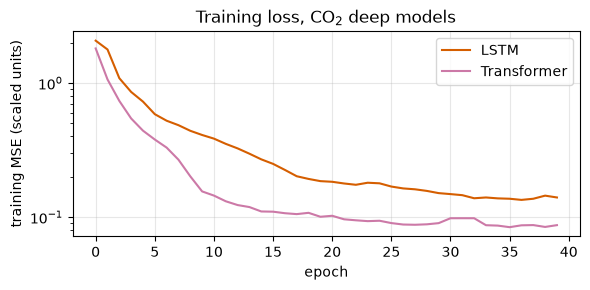

In [16]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(lstm_losses, color=COLORS["LSTM"], lw=1.5, label="LSTM")
ax.plot(tfm_losses, color=COLORS["Transformer"], lw=1.5, label="Transformer")
ax.set_xlabel("epoch")
ax.set_ylabel("training MSE (scaled units)")
ax.set_yscale("log")
ax.set_title("Training loss, CO$_2$ deep models")
ax.legend()
fig.tight_layout()
plt.show()

### 3.6 The comparison

The table is built from `results_co2`, the dictionary that `register()` filled from the predictions.

In [17]:
co2_table = pd.DataFrame(results_co2).T.sort_values("MASE").round(3)
co2_table

,MSE,RMSE,MAE,MAPE (%),MASE
SARIMA,0.129,0.359,0.281,0.067,0.256
Transformer,0.214,0.463,0.358,0.086,0.327
LSTM,1.085,1.042,0.886,0.212,0.808
LightGBM,1.643,1.282,1.030,0.246,0.939
seasonal naive,41.971,6.478,5.961,1.427,5.436
naive,56.380,7.509,6.679,1.596,6.090


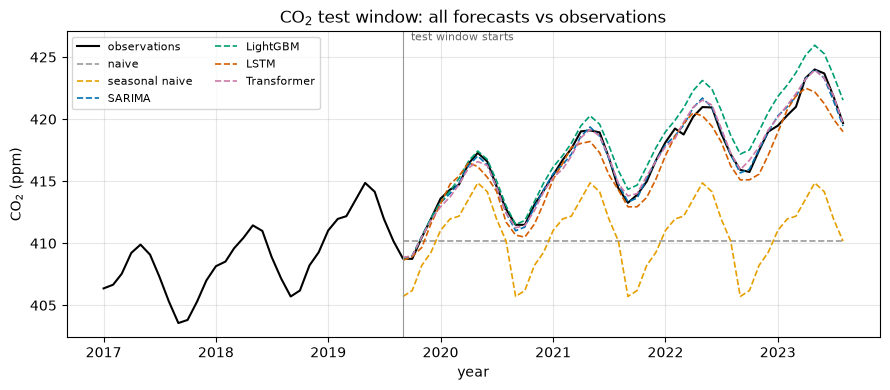

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
recent = y.loc["2017":]
ax.plot(recent.index, recent.values, color=COLORS["observations"],
        lw=1.5, label="observations")
for name, pred in preds_co2.items():
    ax.plot(test_co2.index, pred, color=COLORS[name], lw=1.2, ls="--", label=name)
ax.axvline(test_co2.index[0], color="0.6", lw=0.8)
ax.text(test_co2.index[0], ax.get_ylim()[1], "  test window starts",
        va="top", fontsize=8, color="0.4")
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.set_title("CO$_2$ test window: all forecasts vs observations")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

What to look for:

- **Naive persistence** ignores trend and season. Its MASE is large because a 48-month horizon is much harder than the one-step game MASE is scaled by.
- **Seasonal naive** copies the annual shape but freezes the trend, so it drifts below the observations by about the trend times the horizon. It still beats some trained models.
- **SARIMA** encodes exactly what this series is made of, a differenced trend and a 12-month cycle, in a handful of parameters. On this kind of series it is very hard to beat.
- **LightGBM, LSTM, transformer** must learn trend and season from examples. Recursive feedback (LightGBM) and little training data (the deep pair) both cost accuracy over four years. Capacity is not the bottleneck; the structure of the problem is.

### 3.7 From point forecasts to intervals: the pinball loss, coverage, and CRPS

Every model so far answers "what will CO$_2$ be?" with one number per month. No serious user of a forecast settles for that: a reservoir operator, a carbon-budget analyst, and every operational weather center ask for the *range* of outcomes and how probable each is. The machinery is a small change to what we already have.

A model learns the **quantile** $q_\tau$ of the outcome when it is trained on the **pinball loss** (quantile loss)

$$\mathcal{L}_\tau(y, q) = \max\big(\tau\,(y - q),\ (\tau - 1)(y - q)\big),$$

which charges $\tau$ per unit of under-prediction and $1-\tau$ per unit of over-prediction; the minimizer of its expectation is exactly the $\tau$-quantile. Predict $q_{0.05}$ and $q_{0.95}$ and you have a 90% prediction interval; $q_{0.5}$ is a median point forecast for free.

We give the LSTM from 3.4 a quantile head: instead of 48 numbers it emits $48 \times 19$ — one per horizon step per quantile level $0.05, 0.10, \dots, 0.95$ — trained on the pinball loss averaged over levels. Same windows, same anchoring, same epochs. That buys us a *verifiable* claim, and verification is the point:

- **Empirical coverage**: over the 48 test months, how often does the observation actually fall inside the 90% interval? A calibrated forecast covers about 90%. Less means the model is overconfident; much more means the intervals are too wide to inform any decision. This is the same calibration discipline as the reliability curves of Chapter 3 and notebook 4.7, applied to intervals.
- One wrinkle: quantile outputs trained independently can **cross** ($\hat q_{0.40} > \hat q_{0.45}$ for some month). Sorting along the quantile axis at prediction time is the standard one-line repair, and we apply it below.

In [19]:
QUANTILES = np.round(np.arange(0.05, 0.951, 0.05), 2)   # 0.05, 0.10, ..., 0.95
N_Q = len(QUANTILES)
q_torch = torch.tensor(QUANTILES, dtype=torch.float32, device=device).view(1, 1, -1)

class QuantileLSTMForecaster(nn.Module):
    """The 3.4 LSTM with a (horizon x n_quantiles) head."""
    def __init__(self, horizon, n_q, hidden=32):
        super().__init__()
        self.horizon, self.n_q = horizon, n_q
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, horizon * n_q)
    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.head(h[-1]).view(-1, self.horizon, self.n_q)

def pinball_loss(pred, target):
    """Mean pinball loss over all quantile levels.
    pred: (batch, horizon, n_q); target: (batch, horizon)."""
    diff = target.unsqueeze(-1) - pred
    return torch.mean(torch.maximum(q_torch * diff, (q_torch - 1.0) * diff))

torch.manual_seed(0)
qlstm_co2 = QuantileLSTMForecaster(H_CO2, N_Q).to(device)
ds_q = torch.utils.data.TensorDataset(torch.from_numpy(Xc).unsqueeze(-1),
                                      torch.from_numpy(Yc))
dl_q = torch.utils.data.DataLoader(ds_q, batch_size=32, shuffle=True)
opt_q = torch.optim.Adam(qlstm_co2.parameters(), lr=1e-3)
for _ in range(40):
    qlstm_co2.train()
    for xb, yb in dl_q:
        xb, yb = xb.to(device), yb.to(device)
        opt_q.zero_grad()
        pinball_loss(qlstm_co2(xb), yb).backward()
        opt_q.step()

# Predict the test window, un-anchor, and sort along the quantile axis
# (independently trained quantile outputs can cross; sorting is the repair).
ctx = train_co2.to_numpy()[-CONTEXT_CO2:]
x_q = torch.from_numpy(((ctx - ctx[-1]) / scale_co2)
                       .astype(np.float32)).reshape(1, -1, 1).to(device)
qlstm_co2.eval()
with torch.no_grad():
    q_pred = qlstm_co2(x_q).cpu().numpy()[0]            # (48, 19), scaled units
q_pred = np.sort(q_pred, axis=1) * scale_co2 + ctx[-1]  # back to ppm
lo, med, hi = q_pred[:, 0], q_pred[:, N_Q // 2], q_pred[:, -1]  # q05, q50, q95

### Your turn (2): the coverage of the 90% interval

`lo` and `hi` hold the 5% and 95% quantiles for each of the 48 test months. Write `inside`, a boolean array that is True where the observation `test_co2.values` falls between `lo` and `hi` (inclusive). Its mean is the empirical coverage. One line.

In [20]:
inside = None   # your line here

*Answer below (click to open it).*

In [21]:
inside = (test_co2.values >= lo) & (test_co2.values <= hi)

empirical coverage of the 90% interval: 91.7% (44/48 test months inside)
interval width: 2.33 ppm at 1 month -> 6.27 ppm at 48 months


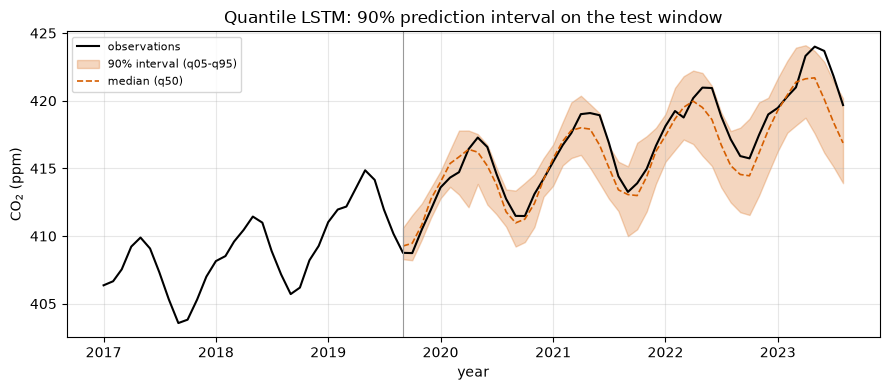

In [22]:
print(f"empirical coverage of the 90% interval: {inside.mean():.1%} "
      f"({inside.sum()}/{len(inside)} test months inside)")
print(f"interval width: {hi[0] - lo[0]:.2f} ppm at 1 month -> "
      f"{hi[-1] - lo[-1]:.2f} ppm at 48 months")

fig, ax = plt.subplots(figsize=(9, 4))
recent = y.loc["2017":]
ax.plot(recent.index, recent.values, color=COLORS["observations"], lw=1.5,
        label="observations")
ax.fill_between(test_co2.index, lo, hi, color=COLORS["LSTM"], alpha=0.25,
                label="90% interval (q05-q95)")
ax.plot(test_co2.index, med, color=COLORS["LSTM"], lw=1.2, ls="--",
        label="median (q50)")
ax.axvline(test_co2.index[0], color="0.6", lw=0.8)
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.set_title("Quantile LSTM: 90% prediction interval on the test window")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In this run the 90% interval catches **44 of 48 test months — 91.7% empirical coverage against a nominal 90%**. That is a calibrated interval, and it was not guaranteed: quantile regression aims at calibration but nothing enforces it out of sample, which is why you compute coverage instead of asserting it. Two honest caveats. First, 48 consecutive months from a single forecast origin are strongly correlated, so this coverage estimate is itself noisy — a different test window could easily return 80% or 100%. Second, look at the printed widths: the interval grows from about 2.3 ppm at one month to about 6.3 ppm at four years. The model learned from the training windows that uncertainty compounds with lead time; nobody told it.

**CRPS.** Coverage checks one interval at one level. The **continuous ranked probability score (CRPS)** — the standard scoring rule of forecast verification, the number atmospheric ensemble systems report — scores the *entire* predictive distribution $F$ against the outcome $y$:

$$\mathrm{CRPS}(F, y) = \int_{-\infty}^{\infty} \big(F(z) - \mathbf{1}\{z \ge y\}\big)^2\, dz \;=\; 2\int_0^1 \mathcal{L}_\tau\big(y, q_\tau\big)\, d\tau .$$

It has the units of the data (ppm here), and for a forecast collapsed to a single point it reduces *exactly* to the absolute error — so mean CRPS is directly comparable to a point forecast's MAE, and it rewards both calibration and sharpness at once. The second identity is also the estimator: average the pinball loss over a dense quantile grid and double it. We already predict 19 quantiles, so the implementation is a few lines.

In [23]:
def crps_from_quantiles(y_true, q_pred, quantiles):
    """Quantile-based CRPS estimator: 2 x the pinball loss averaged over a
    dense quantile grid. Exact in the limit of a dense grid; with 19 levels
    it slightly undervalues the tails beyond q05/q95."""
    yv = np.asarray(y_true, dtype=float).reshape(-1, 1)
    diff = yv - np.asarray(q_pred, dtype=float)
    tau = np.asarray(quantiles, dtype=float).reshape(1, -1)
    return 2.0 * np.maximum(tau * diff, (tau - 1.0) * diff).mean(axis=1)

crps_q = crps_from_quantiles(test_co2.values, q_pred, QUANTILES)
print(f"mean CRPS, quantile LSTM       : {crps_q.mean():.3f} ppm")
print(f"MAE of its median (q50)        : {np.mean(np.abs(test_co2.values - med)):.3f} ppm")
print("point forecasts (CRPS = MAE):")
for name in ["LSTM", "SARIMA"]:
    print(f"  {name:12s}: {results_co2[name]['MAE']:.3f} ppm")

mean CRPS, quantile LSTM       : 0.766 ppm
MAE of its median (q50)        : 1.051 ppm
point forecasts (CRPS = MAE):
  LSTM        : 0.886 ppm
  SARIMA      : 0.281 ppm


Read the three numbers together. The quantile LSTM's mean CRPS (0.766 ppm) beats the MAE of its own median forecast (1.051 ppm) and of the point-forecast LSTM from 3.4 (0.886 ppm): spreading probability over the range where the outcome may fall earns real score even when the center is imperfect. That comparison is the entire argument for probabilistic forecasting, in one line of output. But SARIMA's point forecast still wins at 0.281 ppm — a well-placed point beats an honestly wide distribution. Calibration does not excuse a biased or diffuse center; the verification community's slogan is *sharpness subject to calibration*, and the natural next contestant would be SARIMA's own forecast distribution (`get_forecast(...).conf_int()` gives its intervals — try scoring them).

### 3.8 Error vs lead time: the skill horizon

A single 48-month MAE flattens an entire dimension of forecast quality: **how fast skill decays with lead time**. Atmospheric verification never reports one number; it reports error as a function of lead, because a model that is excellent at 1 month and useless at 12 serves different decisions than one that is mediocre everywhere.

We measure it with a **rolling-origin** evaluation, the way operational systems are scored. The models stay frozen exactly as trained on data through 2019-08 — no retraining. The forecast origin then slides month by month through the test window; at each origin the model sees the observed history up to that month (an operational forecaster always has the latest observations) and issues forecasts for leads 1 through 12. Averaging the absolute error at each lead over all origins gives an error-vs-lead-time curve — with 37 origins per lead rather than the single sample per lead that one 48-month forecast provides.

The vocabulary to take away: the **skill horizon** is the lead time beyond which a model stops beating the reference forecast (persistence, here). Beyond it, the model adds nothing over "no change". Weather models hit their skill horizon around two weeks; the question is where these models hit theirs on CO$_2$.

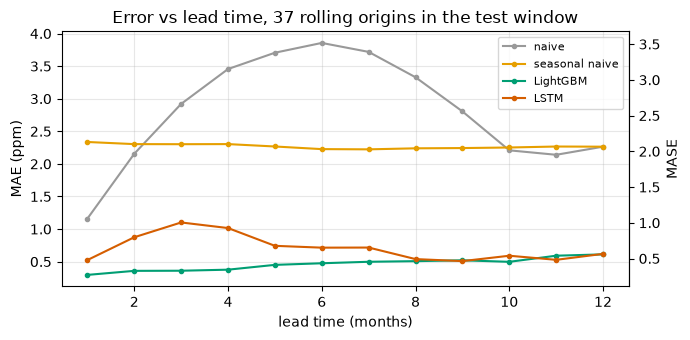

seasonal naive  beats persistence at leads: [3, 4, 5, 6, 7, 8, 9]
LightGBM        beats persistence at leads: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
LSTM            beats persistence at leads: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [24]:
LEADS = 12
LAGS_CO2, ROLL_CO2 = [1, 2, 3, 6, 12, 24], 12
y_vals = y.to_numpy()
first_test = len(train_co2)
origins = np.arange(first_test - 1, len(y) - LEADS)  # index of the last observed month

# One LightGBM fit on the training series only, reused frozen at every origin.
X_tr_lead, y_tr_lead = build_training_table(train_co2, LAGS_CO2, ROLL_CO2)
lgbm_frozen = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15,
                            random_state=0, verbose=-1).fit(X_tr_lead, y_tr_lead)

abs_err = {name: np.zeros((len(origins), LEADS))
           for name in ["naive", "seasonal naive", "LightGBM", "LSTM"]}
for r, j in enumerate(origins):
    hist = y_vals[:j + 1]                        # everything observed at the origin
    target = y_vals[j + 1:j + 1 + LEADS]
    abs_err["naive"][r] = np.abs(target - hist[-1])
    abs_err["seasonal naive"][r] = np.abs(target - y_vals[j + 1 - 12:j + 1 + LEADS - 12])
    h = list(hist)                               # LightGBM: recursive from observed history
    for step in range(LEADS):
        row = pd.DataFrame([lag_feature_row(np.asarray(h), y.index[j + 1 + step],
                                            LAGS_CO2, ROLL_CO2)])
        h.append(h[-1] + float(lgbm_frozen.predict(row)[0]))
    abs_err["LightGBM"][r] = np.abs(target - np.asarray(h[-LEADS:]))
    abs_err["LSTM"][r] = np.abs(target - nn_forecast(lstm_co2, hist[-CONTEXT_CO2:],
                                                     scale_co2)[:LEADS])

leads = np.arange(1, LEADS + 1)
lead_mae = pd.DataFrame({name: e.mean(axis=0) for name, e in abs_err.items()},
                        index=leads)
naive_train_mae_co2 = np.mean(np.abs(np.diff(train_co2.values)))

fig, ax = plt.subplots(figsize=(7, 3.5))
for name in lead_mae.columns:
    ax.plot(leads, lead_mae[name], color=COLORS[name], lw=1.5, marker="o",
            ms=3, label=name)
sec = ax.secondary_yaxis("right", functions=(lambda v: v / naive_train_mae_co2,
                                             lambda v: v * naive_train_mae_co2))
sec.set_ylabel("MASE")
ax.set_xlabel("lead time (months)")
ax.set_ylabel("MAE (ppm)")
ax.set_title(f"Error vs lead time, {len(origins)} rolling origins in the test window")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for name in ["seasonal naive", "LightGBM", "LSTM"]:
    wins = leads[lead_mae[name].values < lead_mae["naive"].values]
    print(f"{name:15s} beats persistence at leads: {wins.tolist()}")

The curve and the printed check answer the skill-horizon question, and on CO$_2$ the answer is the opposite of weather. Persistence degrades steadily with lead — the trend and the seasonal cycle pull the series ever further from "no change" — while the trained models' error grows far more slowly. **LightGBM and the LSTM beat persistence at every lead from 1 to 12 months: their skill horizon lies beyond a year**, past the longest lead we measured. Weather models lose to climatology in about two weeks because atmospheric chaos destroys the information in the initial state; monthly CO$_2$ keeps its skill because the structure that carries the forecast (trend plus annual cycle) never stops applying. The skill horizon is a property of the *series* as much as of the model.

The reference forecasts are still instructive. Seasonal naive beats persistence only at intermediate leads (3 through 9 in this run): at leads 1-2 last month's value is simply very close to the truth, and near lead 12 persistence lands back in the same season, closing most of the gap. So even the choice of reference depends on lead time — one more reason a single-number summary of forecast skill hides more than it shows.

### 3.9 Is the ranking stable? Seed spread

Every number in the 3.6 table came from **one** training run; a table entry is a sample from a distribution over seeds, and reporting a sample as if it were the mean is the same sin as reporting a point forecast without an interval.

The seed sensitivity differs by model class, and that is part of the lesson:

- **naive, seasonal naive, SARIMA** are deterministic: no seed, no spread.
- **LightGBM** takes a `random_state`, but as configured here (no row or feature subsampling) the algorithm is deterministic too — the seed is an inert knob until you enable bagging. We run 5 seeds to demonstrate that, not to estimate a spread.
- **LSTM and transformer** are stochastic twice over: weight initialization and batch shuffling (plus dropout, for the transformer). These are the entries whose table position you should distrust from a single run. They are also the slow entries, so we use 3 seeds each rather than 5 and say so.

In [25]:
def mase_of(pred):
    return forecast_metrics(test_co2.values, pred, train_co2.values)["MASE"]

seed_mase = {}
seed_mase["LightGBM"] = [
    mase_of(lgbm_recursive_forecast(train_co2, test_co2.index,
                                    lags=[1, 2, 3, 6, 12, 24], roll=12,
                                    random_state=s)[0])
    for s in range(5)
]

def deep_seed_mase(model_cls, seed):
    torch.manual_seed(seed)
    m = model_cls(horizon=H_CO2)
    train_forecaster(m, Xc, Yc, epochs=40)
    return mase_of(nn_forecast(m, train_co2.to_numpy()[-CONTEXT_CO2:], scale_co2))

# Seed 0 is the run already in the 3.6 table; two more per deep model. Three
# seeds, not five: these are the slow entries, and the spread they show is
# already unmistakable.
seed_mase["LSTM"] = ([results_co2["LSTM"]["MASE"]]
                     + [deep_seed_mase(LSTMForecaster, s) for s in (1, 2)])
seed_mase["Transformer"] = ([results_co2["Transformer"]["MASE"]]
                            + [deep_seed_mase(TransformerForecaster, s) for s in (1, 2)])

spread_table = pd.DataFrame({
    name: {"MASE mean": np.mean(v), "MASE std": np.std(v),
           "MASE min": np.min(v), "MASE max": np.max(v), "seeds": len(v)}
    for name, v in seed_mase.items()}).T.round(3)
spread_table

,MASE mean,MASE std,MASE min,MASE max,seeds
LightGBM,0.939,0.000,0.939,0.939,5.0
LSTM,0.827,0.021,0.808,0.856,3.0
Transformer,0.356,0.034,0.327,0.403,3.0


The spread table sharpens the 3.6 ranking rather than overturning it — and shows exactly where the randomness lives:

- **LightGBM** posts the identical MASE for all five seeds (std 0.000), as promised: with no row or feature subsampling the algorithm is deterministic, and "we varied the seed" is evidence of robustness only when the algorithm actually consumes the seed.
- **LSTM** spans 0.808-0.856 (mean 0.827, std 0.021); the **transformer** spans 0.327-0.403 (mean 0.356, std 0.034) — a tenth of its own mean, from initialization, batch order, and dropout alone.
- The ranges do not overlap each other, SARIMA's deterministic 0.256, or LightGBM's 0.939, so on this run the shootout order survives the seeds. That conclusion now rests on evidence, and it is not a general law: on a short series the gaps between models can be the size of these spreads. Report mean and spread; let the reader see whether the gaps beat the noise.

## 4. Rare events break bulk metrics

The defining data problem of the geosciences is a field that varies smoothly for years and then does something extreme for three days: floods on a discharge record, eruptions on a tremor record, offsets on a strain record. Every metric in this notebook so far averages over *all* test samples, and quiet samples outnumber event samples by roughly twelve to one — so a model can post an excellent MAE while missing every event that matters.

To show this cleanly we need ground truth about the events, so we build the series ourselves with `mlgeo_synth.inject_rare_events`: eight years of a daily seasonal background, punctuated by ~6 events per year lasting 2-6 days, with amplitudes drawn from a **generalized Pareto distribution** (`tail="gpd"`, shape $\xi = 0.5$). That is a power-law tail — the extreme-value regime of real flood and surge records, where the variance is infinite and the largest event in any future window is routinely several times larger than the largest one yet observed. The generator returns an `amplitude` column: the true drawn size of each event, exactly the ground truth a bulk metric never sees.

The forecaster is deliberately given every advantage: one-step-ahead LightGBM (yesterday's value is always in the feature set), trained on six years, tested on the last two. Then, instead of one MAE, we **stratify** the test error by the ground-truth amplitude.

                        n samples     MAE
all test samples              730   0.969
quiet (no event)              674   0.621
event, amplitude < 10          43   2.458
event, amplitude 10-25          7  10.577
event, amplitude >= 25          6  18.274

largest single miss: 50.8 (event amplitude 50.2)


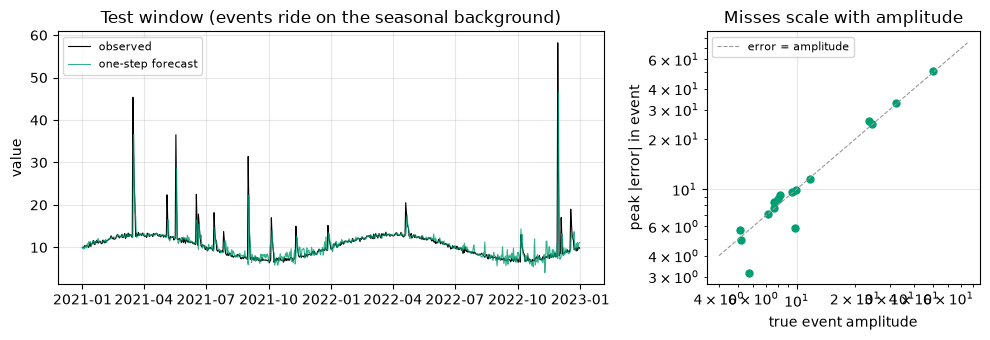

In [26]:
n_days_ev = int(8 * 365.25)
days_ev = pd.date_range("2015-01-01", periods=n_days_ev, freq="D")
rng_ev = np.random.default_rng(0)
background_ev = (10.0 + 3.0 * np.sin(2 * np.pi * np.arange(n_days_ev) / 365.25)
                 + 0.3 * rng_ev.standard_normal(n_days_ev))
events = mlgeo_synth.inject_rare_events(background_ev, rate_per_year=6.0,
                                        duration_days=(2, 6), shape="spike",
                                        tail="gpd", seed=7)
series_ev = pd.Series(events["value"].to_numpy(), index=days_ev)

# One-step-ahead LightGBM on lag features — the easiest possible forecasting
# task: the model always has yesterday's observation in hand.
LAGS_EV, ROLL_EV = [1, 2, 3, 5, 7, 14, 365], 7
X_ev, dy_ev = build_training_table(series_ev, LAGS_EV, ROLL_EV)
start_ev = max(max(LAGS_EV), ROLL_EV)
dates_ev = series_ev.index[start_ev:]
cut = dates_ev.searchsorted(pd.Timestamp("2021-01-01"))   # train < 2021 <= test

lgbm_ev = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15,
                        random_state=0, verbose=-1).fit(X_ev.iloc[:cut], dy_ev[:cut])
pred_ev = (series_ev.to_numpy()[start_ev - 1:-1][cut:]
           + lgbm_ev.predict(X_ev.iloc[cut:]))            # previous value + predicted change
true_ev = series_ev.to_numpy()[start_ev:][cut:]
err_ev = np.abs(true_ev - pred_ev)

# Stratify by the generator's ground-truth amplitude column.
evt = events.iloc[start_ev:].iloc[cut:]                   # aligned truth columns
quiet = evt["event"].to_numpy() == 0
amp = evt["amplitude"].to_numpy()
strata = {
    "all test samples":        np.ones_like(quiet),
    "quiet (no event)":        quiet,
    "event, amplitude < 10":   ~quiet & (amp < 10),
    "event, amplitude 10-25":  ~quiet & (amp >= 10) & (amp < 25),
    "event, amplitude >= 25":  ~quiet & (amp >= 25),
}
tail_table = pd.DataFrame({name: {"n samples": int(m.sum()),
                                  "MAE": err_ev[m].mean()}
                           for name, m in strata.items()}).T
tail_table["n samples"] = tail_table["n samples"].astype(int)
print(tail_table.round(3))
print(f"\nlargest single miss: {err_ev.max():.1f} "
      f"(event amplitude {amp[np.argmax(err_ev)]:.1f})")

# Left: the test window. Right: per-event peak error vs true amplitude.
per_event = (pd.DataFrame({"event_id": evt["event_id"].to_numpy(),
                           "amp": amp, "err": err_ev})
             .query("event_id >= 0").groupby("event_id")
             .agg(amp=("amp", "max"), peak_err=("err", "max")))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5),
                         gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(dates_ev[cut:], true_ev, color=COLORS["observations"], lw=0.8,
             label="observed")
axes[0].plot(dates_ev[cut:], pred_ev, color=COLORS["LightGBM"], lw=0.8,
             alpha=0.8, label="one-step forecast")
axes[0].set_ylabel("value")
axes[0].set_title("Test window (events ride on the seasonal background)")
axes[0].legend(fontsize=8)
axes[1].loglog(per_event["amp"], per_event["peak_err"], "o", ms=5,
               color=COLORS["LightGBM"])
lim = [4, per_event["amp"].max() * 1.5]
axes[1].plot(lim, lim, color="0.6", lw=0.8, ls="--", label="error = amplitude")
axes[1].set_xlabel("true event amplitude")
axes[1].set_ylabel("peak |error| in event")
axes[1].set_title("Misses scale with amplitude")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

A naive reading of the first row says the model is excellent: MAE 0.97 on a series whose seasonal swing alone is 6 units. The stratified rows tell the real story. Quiet days score 0.62 — the noise floor, as good as one-step forecasting gets. Small events (amplitude below 10) already cost 2.5. The seven samples in mid-size events cost about 10.6, the six samples in the largest events 18.3, and the single largest event — amplitude 50.2 — is missed by 50.8: **the model predicted the seasonal background and the flood happened anyway**. The right panel makes it systematic: peak error per event tracks the true amplitude along the error-equals-amplitude line. What the model has never seen, it misses in full.

Both causes are structural, not bugs. Event onsets are unpredictable from lag features — no yesterday-value tells you a spike starts tomorrow — and the GPD tail ($\xi = 0.5$) guarantees that the test window contains amplitudes beyond every training example, so the model is extrapolating precisely on the samples that matter most. Meanwhile the bulk metric hides all of it: event samples are 56 of 730 test days (about one in thirteen), so the overall MAE (0.97) sits within a factor of 1.6 of the quiet-day floor while the top stratum is thirty times worse. A leaderboard scored on overall MAE would congratulate this model.

The repair is in the metric, not the model: if events are what your forecast exists for — floods, eruptions, offsets — score them separately. Stratified tables like this one, event-window recall, or amplitude-weighted losses all work; averaging over the quiet days does not. This is the same fair-evaluation discipline as the hidden leaderboard track below: what you measure is what you optimize, so measure the thing that matters.

## 5. Exercises

**Exercise 1.** In the CO$_2$ LightGBM entry, remove `lag_12` and `lag_24` from the lag list and rerun. What happens to the MASE, and why?

```{admonition} Solution
:class: dropdown
The MASE gets worse. The 12- and 24-month lags are how the model sees the annual cycle; without them it must reconstruct seasonality from the calendar-month feature and short lags alone, and the recursive forecast slowly drifts off the seasonal shape. Run
`lgbm_recursive_forecast(train_co2, test_co2.index, lags=[1, 2, 3, 6], roll=12)`
and compare the metrics with `forecast_metrics`.
```

**Exercise 2.** The deep models forecast all 48 months in one shot (direct multi-step); LightGBM predicts one month at a time and feeds predictions back in (recursive). Name one advantage of each strategy.

```{admonition} Solution
:class: dropdown
Direct: no error feedback, so a bad early step cannot contaminate later steps, and the model is trained on exactly the horizon it is scored on. Recursive: one model serves any horizon, and one-step training uses many more examples per parameter; but errors compound along the horizon. Hybrids (one direct model per step, or "rectify" schemes) exist for exactly this trade-off.
```

**Exercise 3.** Rerun section 4 twice: once with `tail="uniform"` (the generator's default: amplitudes uniform on 5-20) and once keeping `tail="gpd"` but raising `rate_per_year` to 24. Which change does more for the large-event stratum, and what does that tell you about the difference between *rare* and *heavy-tailed*?

```{admonition} Solution
:class: dropdown
The uniform tail helps more. With amplitudes capped at 20, the training window has already shown the model events as large as any it will ever be scored on — the problem is interpolation, and more examples (higher rate) polish it. With a GPD tail the largest future event is beyond every training example almost by construction, so no realistic event rate fixes the top stratum: the model is asked to extrapolate. Rarity limits how many examples you get; a heavy tail guarantees the exam contains a magnitude the textbook never showed. (Notebook 4.7's out-of-distribution exercise is the same lesson in feature space.)
```

## 6. The class leaderboard: two tracks

Now the 12 months we removed in section 1.2 come back into play — but first, an honest disclosure about what a public leaderboard can and cannot measure.

```{admonition} The public CO$_2$ score is a diagnostic — and trivially gameable
:class: warning
The holdout months are public NOAA data. The truth file (`leaderboard/co2_holdout.csv`) is committed to the course repository, and the full Mauna Loa record is cached on your own disk by the `pooch` call in section 1.1. Copying those numbers into a submission scores a perfect MASE of 0.0 — and, more subtly, so does "forecasting" with any model that peeked at the holdout. That is why this track carries **no grading weight**: it exists so you can exercise the submission pipeline and compare honest attempts. A leaderboard is only as meaningful as its holdout is inaccessible — the same reason Chapter 3.5's public classification score is a diagnostic while its grading weight sits on a hidden test set. The graded track below forecasts a series whose future exists only on the instructor's machine.
```

**Track A — CO$_2$ (diagnostic).**

1. Produce a 12-month CO$_2$ forecast for **2023-09 through 2024-08**, the held-out months, using any model trained on data up to 2023-08 only. On your honor — see the box above for why cheating here only defeats the diagnostic.
2. Save it to `results/forecast_<uwnetid>.csv` with exactly two columns: `date` (as `YYYY-MM`) and `co2_ppm`.
3. Submit it via a pull request to the course book repository, [https://github.com/geo-smart/mlgeo-book](https://github.com/geo-smart/mlgeo-book). CI scores each PR and posts the standings.

Scoring is MASE against the held-out months, scaled by the naive one-step MAE of the *training* series (the same convention as `forecast_metrics` in section 2.2 — the denominator comes from the pre-holdout record, not from the holdout itself).

**Track B — the hidden synthetic series (graded).** The file `leaderboard/synth_forecast_history.csv` in the course repository holds a daily displacement series from `mlgeo_synth.gnss_series` — secular trend, annual and semi-annual cycles, and colored noise, like the GNSS records of Chapter 2 — generated from a private seed and regenerated every year. Forecast the **90 days after the last history date** and save `results/forecast_hidden_<uwnetid>.csv` with columns `date` (`YYYY-MM-DD`) and `disp_mm`, submitted in the same pull request. The truth series is never committed; the public leaderboard lists your submission as *received*, and the instructor's run produces the scored table. Same metric: MASE, scaled by the history's naive one-step error.

The cells below write an example file for each track using the recursive LightGBM model. Replace `example` with your UW NetID and the forecasts with your own.

In [27]:
uwnetid = "example"   # <-- replace with your UW NetID

# Track A: refit on ALL pre-holdout data (through 2023-08) and forecast the
# 12 holdout months.
final_pred, _ = lgbm_recursive_forecast(y, holdout_months,
                                        lags=[1, 2, 3, 6, 12, 24], roll=12)

submission = pd.DataFrame({"date": holdout_months.strftime("%Y-%m"),
                           "co2_ppm": np.round(final_pred, 2)})
os.makedirs("results", exist_ok=True)
out_path = f"results/forecast_{uwnetid}.csv"
submission.to_csv(out_path, index=False)
print("wrote", out_path)
print(submission.to_string(index=False))

wrote results/forecast_example.csv
   date  co2_ppm
2023-09   418.23
2023-10   418.42
2023-11   419.86
2023-12   421.29
2024-01   422.44
2024-02   423.25
2024-03   424.07
2024-04   425.49
2024-05   426.23
2024-06   425.65
2024-07   423.90
2024-08   421.89


In [28]:
# Track B: forecast the hidden synthetic series 90 days past its history.
hist_path = Path("../../leaderboard/synth_forecast_history.csv")
if not hist_path.exists():          # running outside the repo checkout
    hist_path = Path(pooch.retrieve(
        "https://raw.githubusercontent.com/geo-smart/mlgeo-book/main/"
        "leaderboard/synth_forecast_history.csv",
        known_hash=None, fname="synth_forecast_history.csv"))
hidden_hist = pd.read_csv(hist_path, parse_dates=["date"])
hidden_series = pd.Series(hidden_hist["disp_mm"].to_numpy(),
                          index=pd.DatetimeIndex(hidden_hist["date"]))
horizon_dates = pd.date_range(hidden_series.index[-1] + pd.Timedelta(days=1),
                              periods=90, freq="D")
print(f"history: {len(hidden_series)} days ending {hidden_series.index[-1].date()}; "
      f"forecast {horizon_dates[0].date()} .. {horizon_dates[-1].date()}")

hidden_pred, _ = lgbm_recursive_forecast(hidden_series, horizon_dates,
                                         lags=[1, 2, 3, 7, 14, 365], roll=7)
hidden_sub = pd.DataFrame({"date": horizon_dates.strftime("%Y-%m-%d"),
                           "disp_mm": np.round(hidden_pred, 3)})
hidden_out = f"results/forecast_hidden_{uwnetid}.csv"
hidden_sub.to_csv(hidden_out, index=False)
print("wrote", hidden_out)
hidden_sub.head()

history: 2832 days ending 2022-10-02; forecast 2022-10-03 .. 2022-12-31


wrote results/forecast_hidden_example.csv


,date,disp_mm
0,2022-10-03,93.733
1,2022-10-04,94.187
2,2022-10-05,93.695
3,2022-10-06,94.463
4,2022-10-07,93.498


## Summary

- Baselines first: naive and seasonal naive set the bar, and MASE measures every model against the one-step naive forecast.
- One temporal split, one metric helper, one table built in code.
- On a long, structured series like CO$_2$, a well-chosen classical model (SARIMA) is hard to beat; deep models need anchoring and scaling just to compete.
- Recursive (LightGBM) and direct (LSTM, transformer) multi-step forecasting are a real design choice.
- A point forecast is the start. A quantile head trained on the pinball loss gives an interval whose coverage you measure; CRPS scores the whole distribution on the scale of the MAE.
- Error depends on lead time; plot it. The skill horizon is the lead at which a model stops beating persistence.
- A ranking from one seed is one sample: report the mean and the spread over seeds.
- A bulk MAE can look excellent while every large rare event is missed. Score events separately.

## Reflection

Two or three sentences each.

1. **What you learned.** Which result of the shootout surprised you most?
2. **What you learned from the agents.** If an assistant wrote part of your leaderboard model, what did you check before submitting?
3. **How to improve it.** What would make this notebook more useful for the forecasting part of your project?